# How well do CLIP features predict macaque IT responses?

| | |
| --- | --- |
| **Question** | How well does a linear map from CLIP ViT-B/32 features predict held-out responses of 168 macaque IT recording sites? |
| **Requires** | CPU only to replot saved predictions (`../assets/clip_majajhong_it.npz`). Recomputing them needs the CLIP model, the MajajHong2015 dataset and several GB of memory; this was done on a GPU host. Replotting takes a few seconds. |
| **Lessons used** | [2. Your first benchmark](../lessons/02_your_first_benchmark.ipynb), [3. Wrap a PyTorch model](../lessons/03_wrap_a_pytorch_model.ipynb), [5. Layers and regions](../lessons/05_layers_and_regions.ipynb) |

## Background

Neural predictivity is the standard Brain-Score test of whether a model's internal
representation resembles a brain region. Features from one model layer are linearly
mapped to recorded responses on training images, and the map is evaluated on held-out
images. The data here are multi-unit responses from macaque IT to 3,200 images
(MajajHong2015, public split), predicted from CLIP ViT-B/32 features with partial least
squares (PLS) regression.

## Hypothesis

The held-out correlation between predicted and measured responses is above the
shuffled-pairing reference for most IT sites.

## Method

The predictions were computed once on a GPU host with the cross-validation in the last
cell of this notebook (10 stratified splits, 90% train, PLS with 25 components) and saved.
Pearson r measures linear association between predicted and measured responses: 0 is no
linear relationship and 1 is perfect. The values are raw correlations without noise-ceiling
normalization.

The next cell loads the saved predictions. The best-predicted site (the argmax over all
sites) is used for the first figure.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

saved = np.load('../assets/clip_majajhong_it.npz')
measured, predicted = saved['measured'], saved['predicted']
best_site = int(saved['best_neuroid'])
best_r = float(saved['best_r'])
median_r = float(saved['median_r'])
site_r = saved['per_neuroid_r']

The reference distribution shuffles which measured response goes with which
predicted response at the best site, 200 times.

In [2]:
rng = np.random.RandomState(0)
shuffled = np.array([np.corrcoef(predicted, rng.permutation(measured))[0, 1] for _ in range(200)])
shuffled_95 = float(np.percentile(np.abs(shuffled), 95))

## Results

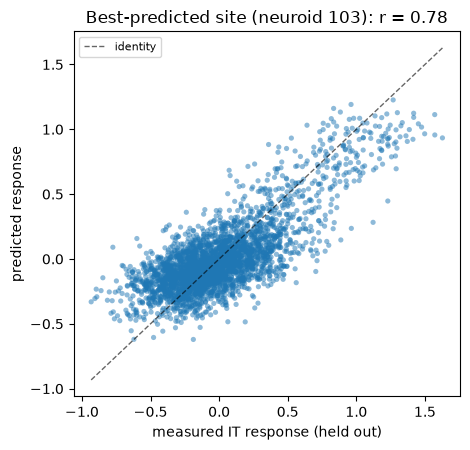

shuffled pairing at this site: |r| < 0.032 in 95% of 200 permutations


In [3]:
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.scatter(measured, predicted, s=14, alpha=0.5, edgecolor='none')
lo, hi = float(np.min([measured, predicted])), float(np.max([measured, predicted]))
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, alpha=0.6, label='identity')
ax.set_xlabel('measured IT response (held out)')
ax.set_ylabel('predicted response')
ax.set_title(f'Best-predicted site (neuroid {best_site}): r = {best_r:.2f}')
ax.legend(fontsize=8, loc='upper left')
fig.tight_layout()
plt.show()
print(f'shuffled pairing at this site: |r| < {shuffled_95:.3f} in 95% of 200 permutations')

Each point is one held-out image. This site was selected because it is the best
predicted, so its correlation is an upper bound for the population and not a typical
value.

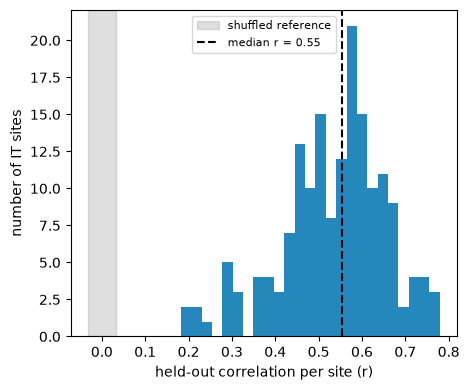

median r = 0.555 over 168 sites; 100% of sites exceed the shuffled reference


In [4]:
fig, ax = plt.subplots(figsize=(4.8, 4.0))
ax.axvspan(-shuffled_95, shuffled_95, color='gray', alpha=0.25, label='shuffled reference')
ax.hist(site_r[~np.isnan(site_r)], bins=25, color='#0072B2', alpha=0.85)
ax.axvline(median_r, c='k', ls='--', label=f'median r = {median_r:.2f}')
ax.set_xlabel('held-out correlation per site (r)')
ax.set_ylabel('number of IT sites')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
above = np.mean(site_r[~np.isnan(site_r)] > shuffled_95)
print(f'median r = {median_r:.3f} over {len(site_r)} sites; '
      f'{above:.0%} of sites exceed the shuffled reference')

The best site has r = 0.78. Across all 168 sites the median is 0.555, and every site
exceeds the shuffled reference of |r| < 0.032.

## Conclusion and limits

CLIP ViT-B/32 features predict held-out IT responses with a raw median correlation of
about 0.55 across sites, well above the shuffled-pairing reference. This shows that the
features carry linearly decodable information about IT responses to these images.

The reference comes from one site and is not corrected for multiple comparisons. The
correlations are not ceiling-normalized, so they are not on the same scale as the
Brain-Score leaderboard values for this benchmark. The figure does not compare CLIP with
other models or with other layers; that requires scoring each of them with the same
benchmark.

The code that produced the saved predictions is shown below for reference. It is not run
here because it needs the model, the dataset and more memory than a laptop provides.

```python
import numpy as np
import brainscore
from scipy.stats import pearsonr
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import StratifiedShuffleSplit
from brainscore_core.streaming_helpers import neural_response

model = brainscore.load_model('clip-vit-b-32')
benchmark = brainscore.load_benchmark('MajajHong2015public.IT-pls-unified')
neural = benchmark._assembly                                 # (3200 images, 168 IT sites)

features = neural_response(model, neural.stimulus_set, record='IT')   # (3200, 38400)
score = benchmark._similarity_metric(features, neural)      # the benchmark's own score

# Repeat the cross-validation to keep the held-out predictions for plotting.
X, Y = np.asarray(features.values), np.asarray(neural.values)
objects = np.asarray(neural['object_name'].values)
splits = StratifiedShuffleSplit(n_splits=10, train_size=0.9, random_state=0)
prediction, count = np.zeros_like(Y, dtype=float), np.zeros(len(Y))
for train, test in splits.split(X, objects):
    pls = PLSRegression(n_components=25, scale=False).fit(X[train], Y[train])
    prediction[test] += pls.predict(X[test])
    count[test] += 1
covered = count > 0
prediction[covered] /= count[covered, None]
site_r = [pearsonr(prediction[covered, j], Y[covered, j])[0] for j in range(Y.shape[1])]
```

The same score is available from `brainscore.score('clip-vit-b-32',
'MajajHong2015public.IT-pls-unified')`.

[Lessons](../lessons/) · [Documentation](../../docs/README.md)